# Machine Translation with Transformers

Corpora: WMT 2024
Le programme semble marcher. Valeurs de Vaswani à atteindre :
* 27,3 avec base, faisceau et moyenne sur le test
* 25,8 avec base et faisceau sur la validation

In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
# Limites mémoire MPS (à définir AVANT "import torch").
# HIGH = plafond d'allocation, en fraction de la mémoire recommandée par Metal :
#   au-delà, PyTorch lève "MPS backend out of memory" au lieu de laisser le
#   pilote geler la machine. LOW doit rester <= HIGH.
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.8"
os.environ["PYTORCH_MPS_LOW_WATERMARK_RATIO"] = "0.6"

In [2]:
import sys
import torch
import torch.nn as nn
from torch.nn import Transformer
from torch import Tensor
from torch.nn.utils.rnn import pad_sequence
import random
from torch.optim.lr_scheduler import LambdaLR
import numpy as np
import math
import matplotlib.pyplot as plt
from tqdm import tqdm
import sentencepiece as spm
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import json
import pandas as pd
import itertools
from timeit import default_timer as timer
from torch.utils.data import BatchSampler
import sacrebleu
from timeit import default_timer as timer

In [3]:
import torch._dynamo
torch._dynamo.config.capture_scalar_outputs = True

In [4]:
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)

In [5]:
DEVICE = torch.device('mps' if torch.backends.mps.is_available() else
                      'cuda' if torch.cuda.is_available() else 'cpu')
DEVICE

device(type='mps')

In [6]:
# DEVICE = 'cpu'

In [7]:
MAX_TOKEN_LEN = 256  # fairseq ne limite pas la longueur ici (pas de
# --max-source-positions / --max-target-positions dans la commande) ;
# 256 est une marge large qui ne tronque plus les phrases WMT en-de.

In [ ]:
EMB_SIZE = 512
NHEAD = 8
FFN_HID_DIM = 4 * EMB_SIZE
NUM_ENCODER_LAYERS = 6
NUM_DECODER_LAYERS = 6

BATCH_SIZE = 24  # 32 : 6,30 (en fait plus), 64 : 15 24 : 6,50
# ACCU_CNT = 26
# Micro-lots d'entraînement, BATCH_SIZE phrases par lot
# (tranches de longueur voisine), AVEC en plus un plafond de mémoire :
# phrases par lot = min(BATCH_SIZE, MAX_TOKENS_PER_BATCH // longueur_de_la_tranche)
# Avec 2048, les lots de phrases de 80 tokens ou moins sont de 24 phrases ; seuls les lots de phrases plus longues sont réduits
# (22 phrases vers 90 tokens, 8 vers 250), pour ne pas dépasser ~2048 tokens.
# MAX_TOKENS_PER_BATCH = None : 24 phrases,
# jusqu'à 6144 tokens par lot, sans plafond : risque de manque de mémoire).
MAX_TOKENS_PER_BATCH = 1536  # 1536  # 1024 #2048

## Dataset

In [9]:
data_dir = Path('wmt14')

In [10]:
train_src = data_dir / 'train.en'
train_tgt = data_dir / 'train.de'
val_src = data_dir / 'validation.en'
val_tgt = data_dir / 'validation.de'
test_src = data_dir / 'test.en'
test_tgt = data_dir / 'test.de'

In [11]:
train = data_dir / 'train.json'
val = data_dir / 'validation.json'
test = data_dir / 'test.json'

In [12]:
print(f"Loading {train}...")
train_dict = pd.read_json(train, lines=True).to_dict(orient='records')
print(f"Loading {val}...")
val_dict = pd.read_json(val, lines=True).to_dict(orient='records')
print(f"Loading {test}...")
test_dict = pd.read_json(test, lines=True).to_dict(orient='records')

Loading wmt14/train.json...
Loading wmt14/validation.json...
Loading wmt14/test.json...


In [13]:
train_input_texts = [item['translation']['en'].strip() for item in train_dict]
train_target_texts = [item['translation']['de'].strip() for item in train_dict]

In [14]:
val_input_texts = [item['translation']['en'].strip() for item in val_dict]
val_target_texts = [item['translation']['de'].strip() for item in val_dict]

In [ ]:
import gc
test_input_texts = [item['translation']['en'].strip() for item in test_dict]
test_target_texts = [item['translation']['de'].strip() for item in test_dict]

# Les dictionnaires ne servent plus : on libère plusieurs Go de RAM.
for _n in ('train_dict', 'val_dict', 'test_dict'):
    globals().pop(_n, None)
gc.collect()

0

In [16]:
train_target_texts[:2]

['Wiederaufnahme der Sitzungsperiode',
 'Ich erkläre die am Freitag, dem 17. Dezember unterbrochene Sitzungsperiode des Europäischen Parlaments für wiederaufgenommen, wünsche Ihnen nochmals alles Gute zum Jahreswechsel und hoffe, daß Sie schöne Ferien hatten.']

In [17]:
len(train_input_texts), len(train_target_texts), len(
    val_input_texts), len(val_target_texts), len(test_input_texts), len(test_target_texts)

(4508785, 4508785, 3000, 3000, 3003, 3003)

In [18]:
print(train_input_texts[1000])
print(train_target_texts[1000])
print(val_input_texts[1000])
print(val_target_texts[1000])
print(test_input_texts[1000])
print(test_target_texts[1000])

In this respect, we should heed the words of von Eieck, and doubtless also those of the great Italian liberal Bruno Leoni, who warned precisely against the risks of an abnormal increase in anti-competition policies.
In dieser Hinsicht dürften wohl die Schriften von von Eieck und sicherlich auch die eines bedeutenden italienischen Liberalen wie Bruno Leoni hilfreich für uns sein, der eben vor den Gefahren einer außergewöhnlichen Zunahme politischer Maßnahmen gegen wettbewerbswidrige Praktiken warnte.
NKU Head: Svarc System audit has failed because of politicians.
NKÚ-Chef: Kontrolle des Schwarz-Systems versagt durch Verschulden der Politik
Drama in Uruguay: Boys kill playmate with machetes
Drama in Uruguay: Jungen töten Spielkamderaden mit Machete


In [19]:
num_samples = len(train_input_texts)
num_samples

4508785

In [21]:
sp = spm.SentencePieceProcessor()
sp.load(str(data_dir / 'spm.model'))

True

In [22]:
VOCAB_SIZE = len(sp)
VOCAB_SIZE

37000

In [23]:
UNK_IDX, BOS_IDX, EOS_IDX, PAD_IDX = sp.unk_id(
), sp.bos_id(), sp.eos_id(), sp.pad_id()
UNK_IDX, BOS_IDX, EOS_IDX, PAD_IDX

(1, 2, 3, 0)

In [24]:
def text2codes(texts, sp, max_len=MAX_TOKEN_LEN):
    codes = []
    for text in texts:
        # add_bos=True, add_eos=True pour ajouter BOS et EOS
        code = sp.encode(text, out_type=int, add_bos=True,
                         add_eos=True)[:max_len]
        codes.append(torch.tensor(code))
    return codes

In [25]:
train_input_texts[:3], train_target_texts[:3]

(['Resumption of the session',
  'I declare resumed the session of the European Parliament adjourned on Friday 17 December 1999, and I would like once again to wish you a happy new year in the hope that you enjoyed a pleasant festive period.',
  "Although, as you will have seen, the dreaded 'millennium bug' failed to materialise, still the people in a number of countries suffered a series of natural disasters that truly were dreadful."],
 ['Wiederaufnahme der Sitzungsperiode',
  'Ich erkläre die am Freitag, dem 17. Dezember unterbrochene Sitzungsperiode des Europäischen Parlaments für wiederaufgenommen, wünsche Ihnen nochmals alles Gute zum Jahreswechsel und hoffe, daß Sie schöne Ferien hatten.',
  'Wie Sie feststellen konnten, ist der gefürchtete "Millenium-Bug " nicht eingetreten. Doch sind Bürger einiger unserer Mitgliedstaaten Opfer von schrecklichen Naturkatastrophen geworden.'])

In [26]:
text2codes(train_input_texts[:3], sp)

[tensor([    2,  2363, 27628,   304,   279,  9804,     3]),
 tensor([    2,   320, 18524, 24229,   279,  9804,   304,   279,   662,  1103,
         11487,  5293,   314,   382, 13058,  2643,  6046, 18095,   310,   320,
           794,   964,  3371,  1224,   311,  2608,   533,   263,  6878,   876,
           956,   285,   279,  2563,   391,   533, 13424,   263,  8146,  1713,
           488,  3086, 33413,     3]),
 tensor([    2,  6651, 33412,   441,   533,   536,   518,  4696, 33412,   279,
           265,  1548,   314,  1286, 33406,   430,   622,  1384, 17402, 33454,
          9825,   311,  3230,   631, 33412,  1827,   279,  1113,   285,   263,
          1669,   304,  1174, 14612,   263,  5521,   304,  4021, 15095,   391,
          9296,  1114,   265,  1548,  1311, 33413,     3])]

In [27]:
text2codes(train_target_texts[:3], sp)

[tensor([    2, 27577,   317, 26416,     3]),
 tensor([    2,   762, 32508,   315,   634, 14134, 33412,   480, 11197,  6176,
         18395, 33393, 26416,   431,  1084,  2319,   427, 27751,  2331, 33412,
         15635,  1361, 11016,  2950, 18884,   803,  3749, 10102,   318,  4349,
         33412,   926,   491, 10227,  5683,  4732, 33413,     3]),
 tensor([    2,  1778,   491,  9339,  6488, 33412,   420,   317,  2231,   376,
           824,   289,   666, 33425, 20670,  1384, 33429, 33428,   500,   666,
           495, 28247, 33413,  4722,   575,  1905,  9396,  1576,  1421,  7304,
           405, 27970,  3362, 21659,  6537, 33413,     3])]

In [28]:
def codes2text(codes, sp):
    texts = []
    for code in codes:
        # Pas besoin d'option spéciale pour le décodage
        text = sp.decode(code.tolist())
        texts.append(text)
    return texts

In [29]:
codes2text(text2codes(train_input_texts[:3], sp), sp)

['Resumption of the session',
 'I declare resumed the session of the European Parliament adjourned on Friday 17 December 1999, and I would like once again to wish you a happy new year in the hope that you enjoyed a pleasant festive period.',
 "Although, as you will have seen, the dreaded 'millennium bug' failed to materialise, still the people in a number of countries suffered a series of natural disasters that truly were dreadful."]

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self,
                 emb_size: int,
                 dropout: float,
                 maxlen: int = 5000):
        super().__init__()
        self.scale = emb_size ** 0.5
        den = torch.exp(- torch.arange(0, emb_size, 2)
                        * math.log(10000) / emb_size)
        pos = torch.arange(0, maxlen).reshape(maxlen, 1)
        pos_embedding = torch.zeros((maxlen, emb_size))
        pos_embedding[:, 0::2] = torch.sin(pos * den)
        pos_embedding[:, 1::2] = torch.cos(pos * den)
        pos_embedding = pos_embedding.unsqueeze(0)
        self.dropout = nn.Dropout(dropout)
        # Forcez impérativement le type dans le __init__ de PositionalEncoding
        self.register_buffer('pos_embedding', pos_embedding)
        self.emb_size = emb_size

    def forward(self, token_embedding: Tensor):
        return self.dropout(
            token_embedding * self.scale +
            self.pos_embedding[:, :token_embedding.size(1), :]
        )

In [31]:
pe = PositionalEncoding(10, 0.1)

In [32]:
torch.zeros(1, 5, 10)

tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]]])

In [33]:
pe(torch.zeros(1, 5, 10))

tensor([[[ 0.0000e+00,  1.1111e+00,  0.0000e+00,  1.1111e+00,  0.0000e+00,
           1.1111e+00,  0.0000e+00,  1.1111e+00,  0.0000e+00,  0.0000e+00],
         [ 9.3497e-01,  6.0034e-01,  1.7536e-01,  1.0972e+00,  2.7907e-02,
           1.1108e+00,  4.4234e-03,  1.1111e+00,  7.0106e-04,  1.1111e+00],
         [ 1.0103e+00, -4.6239e-01,  3.4633e-01,  1.0558e+00,  5.5796e-02,
           1.1097e+00,  8.8467e-03,  1.1111e+00,  1.4021e-03,  1.1111e+00],
         [ 0.0000e+00, -1.1000e+00,  5.0862e-01,  9.8787e-01,  8.3650e-02,
           0.0000e+00,  1.3270e-02,  1.1110e+00,  2.1032e-03,  1.1111e+00],
         [-8.4089e-01, -7.2627e-01,  0.0000e+00,  8.9521e-01,  1.1145e-01,
           1.1055e+00,  1.7693e-02,  1.1110e+00,  2.8043e-03,  1.1111e+00]]])

In [ ]:
class Seq2SeqTransformer(nn.Module):
    def __init__(self,
                 num_encoder_layers: int,
                 num_decoder_layers: int,
                 emb_size: int,
                 nhead: int,
                 vocab_size: int,
                 dim_feedforward: int = 2048,
                 dropout: float = 0.1):
        super().__init__()
        self.transformer = Transformer(d_model=emb_size,
                                       nhead=nhead,
                                       num_encoder_layers=num_encoder_layers,
                                       num_decoder_layers=num_decoder_layers,
                                       dim_feedforward=dim_feedforward,
                                       dropout=dropout,
                                       batch_first=True)

        self.emb_size = emb_size
        self.embedding = nn.Embedding(
            vocab_size, emb_size, padding_idx=PAD_IDX)
        self.positional_encoding = PositionalEncoding(
            emb_size, dropout=dropout)

        self.generator = nn.Linear(emb_size, vocab_size, bias=False)
        self.generator.weight = self.embedding.weight

    def forward(self,
                src: Tensor,
                trg: Tensor,
                src_mask: Tensor,
                tgt_mask: Tensor,
                src_padding_mask: Tensor,
                tgt_padding_mask: Tensor,
                memory_key_padding_mask: Tensor):
        src_emb = self.positional_encoding(self.embedding(src))
        tgt_emb = self.positional_encoding(self.embedding(trg))
        outs = self.transformer(src_emb, tgt_emb,
                                src_mask=None,
                                tgt_mask=tgt_mask,
                                memory_mask=None,
                                src_key_padding_mask=src_padding_mask,
                                tgt_key_padding_mask=tgt_padding_mask,
                                memory_key_padding_mask=memory_key_padding_mask)
        # tgt_is_causal=True)

        return self.generator(outs)

    def encode(self, src: Tensor, src_mask: Tensor):
        return self.transformer.encoder(self.positional_encoding(
            self.embedding(src)), src_mask)

    def decode(self, tgt: Tensor, memory: Tensor, tgt_mask: Tensor):
        return self.transformer.decoder(self.positional_encoding(
            self.embedding(tgt)), memory,
            tgt_mask)

In [35]:
nn.Transformer.generate_square_subsequent_mask(10)

tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [36]:
def create_mask(src, tgt, pad_idx=PAD_IDX):
    tgt_seq_len = tgt.shape[-1]
    # Génère le masque directement sur le device de tgt
    tgt_mask = nn.Transformer.generate_square_subsequent_mask(
        tgt_seq_len).to(tgt.device).bool()
    # Il est déjà float (0 et -inf), mais on peut le garder ainsi
    src_padding_mask = (src == pad_idx).to(tgt.device)
    tgt_padding_mask = (tgt == pad_idx).to(tgt.device)
    return None, tgt_mask, src_padding_mask, tgt_padding_mask

In [37]:
src = pad_sequence(text2codes(
    train_input_texts[:3], sp), batch_first=True, padding_value=PAD_IDX)
tgt = pad_sequence(text2codes(
    train_target_texts[:3], sp), batch_first=True, padding_value=PAD_IDX)

In [38]:
train_input_texts[:3], train_target_texts[:3]

(['Resumption of the session',
  'I declare resumed the session of the European Parliament adjourned on Friday 17 December 1999, and I would like once again to wish you a happy new year in the hope that you enjoyed a pleasant festive period.',
  "Although, as you will have seen, the dreaded 'millennium bug' failed to materialise, still the people in a number of countries suffered a series of natural disasters that truly were dreadful."],
 ['Wiederaufnahme der Sitzungsperiode',
  'Ich erkläre die am Freitag, dem 17. Dezember unterbrochene Sitzungsperiode des Europäischen Parlaments für wiederaufgenommen, wünsche Ihnen nochmals alles Gute zum Jahreswechsel und hoffe, daß Sie schöne Ferien hatten.',
  'Wie Sie feststellen konnten, ist der gefürchtete "Millenium-Bug " nicht eingetreten. Doch sind Bürger einiger unserer Mitgliedstaaten Opfer von schrecklichen Naturkatastrophen geworden.'])

In [39]:
src

tensor([[    2,  2363, 27628,   304,   279,  9804,     3,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0],
        [    2,   320, 18524, 24229,   279,  9804,   304,   279,   662,  1103,
         11487,  5293,   314,   382, 13058,  2643,  6046, 18095,   310,   320,
           794,   964,  3371,  1224,   311,  2608,   533,   263,  6878,   876,
           956,   285,   279,  2563,   391,   533, 13424,   263,  8146,  1713,
           488,  3086, 33413,     3,     0,     0,     0],
        [    2,  6651, 33412,   441,   533,   536,   518,  4696, 33412,   279,
           265,  1548,   314,  1286, 33406,   430,   622,  1384, 17402, 33454,
          9825,   311,  3230,   631, 33412,  1827,   279,  1113,   285,   263,
          166

In [40]:
tgt

tensor([[    2, 27577,   317, 26416,     3,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0],
        [    2,   762, 32508,   315,   634, 14134, 33412,   480, 11197,  6176,
         18395, 33393, 26416,   431,  1084,  2319,   427, 27751,  2331, 33412,
         15635,  1361, 11016,  2950, 18884,   803,  3749, 10102,   318,  4349,
         33412,   926,   491, 10227,  5683,  4732, 33413,     3],
        [    2,  1778,   491,  9339,  6488, 33412,   420,   317,  2231,   376,
           824,   289,   666, 33425, 20670,  1384, 33429, 33428,   500,   666,
           495, 28247, 33413,  4722,   575,  1905,  9396,  1576,  1421,  7304,
           405, 27970,  3362, 21659,  6537, 33413,     3,     0]])

In [41]:
create_mask(src, tgt)

(None,
 tensor([[False,  True,  True,  ...,  True,  True,  True],
         [False, False,  True,  ...,  True,  True,  True],
         [False, False, False,  ...,  True,  True,  True],
         ...,
         [False, False, False,  ..., False,  True,  True],
         [False, False, False,  ..., False, False,  True],
         [False, False, False,  ..., False, False, False]]),
 tensor([[False, False, False, False, False, False, False,  True,  True,  True,
           True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
           True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
           True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
           True,  True,  True,  True,  True,  True,  True],
         [False, False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False, False,
   

In [42]:
def rate(step, model_size, factor, warmup):
    if step == 0:
        step = 1
    return factor * (
        model_size ** (-0.5) * min(step ** (-0.5), step * warmup ** (-1.5))
    )

In [ ]:
transformer = Seq2SeqTransformer(NUM_ENCODER_LAYERS, NUM_DECODER_LAYERS, EMB_SIZE,
                                 NHEAD, VOCAB_SIZE, FFN_HID_DIM)

for p in transformer.parameters():
    if p.dim() > 1:
        nn.init.xavier_uniform_(p)

transformer.to(DEVICE)
# Le fastpath 'nested tensor' de nn.TransformerEncoder tente de verifier
# l'alignement du masque via un op non supporte sur MPS
# (aten::_nested_tensor_from_mask_left_aligned), ce qui force un aller-
# retour CPU a chaque forward. On desactive ce chemin : sur MPS il n'apporte
# aucun gain de toute façon.
transformer.transformer.encoder.enable_nested_tensor = False
# transformer = torch.compile(transformer, mode='reduce-overhead')
# transformer = torch.compile(transformer, mode='default')
# transformer = torch.compile(transformer)

# reduction='sum' : on ne normalise plus ici. train_step_variable accumule les
# gradients de tous les micro-batches d'un pas puis divise UNE SEULE FOIS par
# le nombre reel de tokens cible vus dans le pas (façon fairseq --max-tokens).
loss_fn = torch.nn.CrossEntropyLoss(
    ignore_index=PAD_IDX, label_smoothing=0.1, reduction='sum')

optimizer = torch.optim.Adam(
    transformer.parameters(), lr=1, betas=(0.9, 0.98), eps=1e-9
)
lr_scheduler = LambdaLR(
    optimizer=optimizer,
    lr_lambda=lambda step: rate(
        step, model_size=transformer.emb_size, factor=1.0, warmup=4000
    ),
)

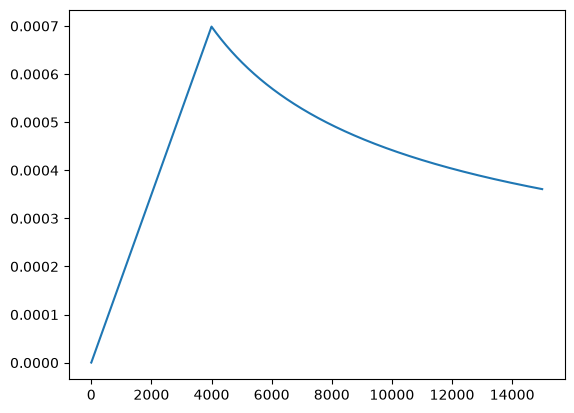

In [44]:
plt.plot([rate(i, transformer.emb_size, 1.0, 4000)
         for i in range(0, 15*1000)])

In [45]:
class PairDataset(Dataset):
    def __init__(self, input_texts, target_texts, sp, max_len=MAX_TOKEN_LEN):
        self.sp = sp
        self.max_len = max_len

        # On encode entièrement (sans troncature) pour connaître la vraie
        # longueur de chaque phrase, puis on ÉCARTE les paires qui dépassent
        # max_len au lieu de les tronquer. Tronquer après add_eos=True
        # supprime l'EOS et coupe la cible en plein milieu : le modèle
        # apprend alors des séquences qui ne se terminent jamais proprement.
        # fairseq filtre ces exemples (max-source-positions /
        # max-target-positions), il ne les tronque jamais : on fait pareil.
        self.input_texts = []
        self.target_texts = []
        self.lengths = []

        n_dropped = 0
        for src_text, tgt_text in zip(input_texts, target_texts):
            src_len = len(sp.encode(src_text, out_type=int,
                          add_bos=True, add_eos=True))
            tgt_len = len(sp.encode(tgt_text, out_type=int,
                          add_bos=True, add_eos=True))
            if src_len <= max_len and tgt_len <= max_len:
                self.input_texts.append(src_text)
                self.target_texts.append(tgt_text)
                self.lengths.append(max(src_len, tgt_len))
            else:
                n_dropped += 1

        print(f"PairDataset: {n_dropped} paires écartées (> {max_len} tokens) "
              f"sur {len(input_texts)}, {len(self.input_texts)} conservées.")

    def __len__(self):
        return len(self.input_texts)

    def __getitem__(self, idx):
        # Plus besoin de [:max_len] ici : tout ce qui est conservé tient
        # déjà dans max_len, EOS inclus.
        src = torch.tensor(self.sp.encode(
            self.input_texts[idx], out_type=int, add_bos=True, add_eos=True))
        tgt = torch.tensor(self.sp.encode(
            self.target_texts[idx], out_type=int, add_bos=True, add_eos=True))
        return src, tgt, self.lengths[idx]   # on retourne aussi la longueur

In [ ]:
import math


class BucketBatchSampler(BatchSampler):
    """ tranches de longueur (bornes 10, 20, ... + une tranche de
    débordement), lots de BATCH_SIZE phrases tirés dans chaque tranche, puis
    mélange global des lots. Ajout : si max_tokens est donné, un lot ne contient
    pas plus de max_tokens // longueur_de_la_tranche phrases (plafond mémoire).
    Avec max_tokens=None, autre comportement.
    """

    def __init__(self, lengths, batch_size, max_tokens=None,
                 bucket_boundaries=None, shuffle=True, drop_last=False):
        self.lengths = lengths
        self.batch_size = batch_size
        self.max_tokens = max_tokens
        self.shuffle = shuffle
        self.drop_last = drop_last
        if bucket_boundaries is None:
            bucket_boundaries = list(range(10, MAX_TOKEN_LEN + 1, 10))
        self.bucket_boundaries = bucket_boundaries
        self.buckets = self._create_buckets()   # liste de (longueur max, indices)

    def _create_buckets(self):
        # +1 : débordement
        buckets = [[] for _ in range(len(self.bucket_boundaries) + 1)]
        for idx, l in enumerate(self.lengths):
            for i, boundary in enumerate(self.bucket_boundaries):
                if l <= boundary:
                    buckets[i].append(idx)
                    break
            else:
                buckets[-1].append(idx)
        longest = list(self.bucket_boundaries) + \
            [max(MAX_TOKEN_LEN, self.bucket_boundaries[-1])]
        return [(L, b) for L, b in zip(longest, buckets) if len(b) > 0]

    def _bs(self, longest):
        if self.max_tokens is None:
            return self.batch_size
        return max(1, min(self.batch_size, self.max_tokens // longest))

    def __iter__(self):
        all_batches = []
        for longest, bucket in self.buckets:
            bs = self._bs(longest)
            if self.shuffle:
                indices = torch.randperm(len(bucket)).tolist()
                bucket = [bucket[i] for i in indices]
            for i in range(0, len(bucket), bs):
                batch = bucket[i:i + bs]
                if len(batch) == bs or not self.drop_last:
                    all_batches.append(batch)
        if self.shuffle:
            # Mélange global de tous les batches
            random.shuffle(all_batches)
        for batch in all_batches:
            yield batch

    def __len__(self):
        total = 0
        for longest, bucket in self.buckets:
            bs = self._bs(longest)
            total += (len(bucket) //
                      bs) if self.drop_last else math.ceil(len(bucket) / bs)
        return total

In [ ]:
import torch.nn.functional as F


def _round_up(n, m=8):
    return -(-n // m) * m


def collate_train(batch):
    """Remplissage (padding) arrondi pour que les formes des tenseurs se
    répètent : MPS garde un graphe en cache par forme, donc moins de formes
    différentes = moins de compilations et une mémoire qui grossit moins.
    src : longueur multiple de 8 ; tgt : (longueur - 1) multiple de 8, car le
    décodeur reçoit tgt[:, :-1]. Les masques de padding rendent ce
    remplissage sans effet sur les résultats.
    """
    src = pad_sequence([b[0] for b in batch],
                       batch_first=True, padding_value=PAD_IDX)
    tgt = pad_sequence([b[1] for b in batch],
                       batch_first=True, padding_value=PAD_IDX)
    src_len = _round_up(src.size(1))
    tgt_len = _round_up(tgt.size(1) - 1) + 1
    src = F.pad(src, (0, src_len - src.size(1)), value=PAD_IDX)
    tgt = F.pad(tgt, (0, tgt_len - tgt.size(1)), value=PAD_IDX)
    return src, tgt


train_dataset = PairDataset(train_input_texts, train_target_texts, sp)
bucket_sampler = BucketBatchSampler(
    lengths=train_dataset.lengths,
    batch_size=BATCH_SIZE,
    max_tokens=MAX_TOKENS_PER_BATCH,
    shuffle=True,
    drop_last=False
)
train_dataloader = DataLoader(
    train_dataset,
    batch_sampler=bucket_sampler,
    collate_fn=collate_train,
    pin_memory=False
)

PairDataset: 1243 paires écartées (> 256 tokens) sur 4508785, 4507542 conservées.


In [48]:
val_dataset = PairDataset(val_input_texts, val_target_texts, sp)
val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    collate_fn=lambda batch: (
        pad_sequence([b[0] for b in batch], batch_first=True,
                     padding_value=PAD_IDX),
        pad_sequence([b[1] for b in batch],
                     batch_first=True, padding_value=PAD_IDX)
    ),
    pin_memory=False
)

PairDataset: 0 paires écartées (> 256 tokens) sur 3000, 3000 conservées.


In [ ]:
# forme du dernier lot + mémoire MPS après forward (diagnostic OOM)
LAST_SHAPES = None


def train_step_variable(model, optimizer, train_iter, dataloader, target_tokens_per_step, loss_fn, PAD_IDX, DEVICE):
    global LAST_SHAPES
    model.train()
    # Accumulation en tenseurs sur le device : on evite les .item() (donc les
    # synchronisations MPS) a chaque micro-batch, un seul aller-retour CPU en
    # fin de pas.
    # somme brute des loss, pour affichage
    total_loss = torch.zeros((), device=DEVICE)
    total_correct = torch.zeros((), device=DEVICE)
    # tokens CIBLE (entier Python), pour affichage
    total_tokens = 0
    optimizer.zero_grad()

    # budget "facon fairseq" : max(longueur src, longueur tgt) par phrase, somme sur le batch
    accu_tokens = 0
    accu_tgt_tokens = 0    # tokens CIBLE uniquement : normalisation du gradient
    steps_done = 0

    while accu_tokens < target_tokens_per_step:
        try:
            src, tgt = next(train_iter)
        except StopIteration:
            train_iter = iter(dataloader)
            src, tgt = next(train_iter)

        # Les comptes de tokens se font ICI, sur le CPU (src et tgt viennent du
        # DataLoader, donc sont encore sur le CPU) : int() sur un tenseur MPS
        # forcerait une synchronisation avec le GPU à chaque micro-lot.
        mask_cpu = (tgt[:, 1:] != PAD_IDX)
        # fairseq (--max-tokens) ne compte pas src+tgt : pour chaque phrase du
        # batch il prend max(longueur_src, longueur_tgt), puis somme sur le
        # batch. On reproduit ici la formule exacte de fairseq.
        # longueur par phrase, côté source
        src_lens = (src != PAD_IDX).sum(dim=1)
        # longueur par phrase, côté cible
        tgt_lens = mask_cpu.sum(dim=1)
        batch_tokens = int(torch.maximum(src_lens, tgt_lens).sum())
        tgt_tokens = int(tgt_lens.sum())

        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        tgt_input, tgt_out = tgt[:, :-1], tgt[:, 1:]
        mask = (tgt_out != PAD_IDX)

        src_mask, tgt_mask, src_padding_mask, tgt_padding_mask = create_mask(
            src, tgt_input)

        # Forward avec eventuel autocast (à décommenter si nécessaire)
        # with torch.autocast(device_type='mps', dtype=torch.float16):
        logits = model(src, tgt_input, src_mask, tgt_mask,
                       src_padding_mask, tgt_padding_mask,
                       memory_key_padding_mask=src_padding_mask)

        if DEVICE.type == 'mps':
            LAST_SHAPES = (tuple(src.shape), tuple(tgt.shape),
                           round(torch.mps.current_allocated_memory() / 2**30, 2))

        # loss_fn est en reduction='sum' : perte brute (non normalisée) pour ce
        # micro-batch. backward() ACCUMULE les gradients à chaque appel ; sommer
        # les perte brutes sur tous les micro-batches puis diviser une seule fois
        # à la fin équivaut exactement à calculer la perte sur le batch entier
        # d'un coup, sans jamais matérialiser ce batch entier en mémoire.
        loss = loss_fn(logits.reshape(-1, logits.size(-1)),
                       tgt_out.reshape(-1))
        # end with autocast
        loss.backward()

        with torch.no_grad():
            total_loss += loss.detach()
            preds = logits.argmax(dim=-1)
            total_correct += ((preds == tgt_out) & mask).sum()
            total_tokens += tgt_tokens

        del logits, loss
        accu_tokens += batch_tokens
        accu_tgt_tokens += tgt_tokens
        steps_done += 1

    # Normalisation façon fairseq : diviser le gradient accumulé par le nombre
    # RÉEL de tokens cible vus dans ce pas.
    for p in model.parameters():
        if p.grad is not None:
            p.grad.div_(max(accu_tgt_tokens, 1))

    optimizer.step()
    if lr_scheduler:
        lr_scheduler.step()
    optimizer.zero_grad()

    avg_loss = (total_loss / total_tokens).item() if total_tokens > 0 else 0
    accuracy = (total_correct / total_tokens).item() if total_tokens > 0 else 0
    return avg_loss, accuracy, train_iter

In [ ]:
def evaluate(model, dataloader, loss_fn, PAD_IDX, DEVICE, max_batches=None):
    """
    Évalue le modèle sur le dataloader.
    max_batches: Permet d'évaluer sur un sous-ensemble pour aller plus vite entre les steps.
    """
    model.eval()
    total_loss = 0
    total_correct = 0
    total_tokens = 0

    # On désactive le calcul du gradient pour économiser la mémoire de la M3
    with torch.no_grad():
        for i, (src, tgt) in enumerate(dataloader):
            if max_batches and i >= max_batches:
                break

            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            tgt_input = tgt[:, :-1]
            tgt_out = tgt[:, 1:]

            # Recréation des masques (sans training, seul le padding et le masque causal comptent)
            src_mask, tgt_mask, src_padding_mask, tgt_padding_mask = create_mask(
                src, tgt_input)

            logits = model(
                src=src,
                trg=tgt_input,
                src_mask=src_mask,
                tgt_mask=tgt_mask,
                src_padding_mask=src_padding_mask,
                tgt_padding_mask=tgt_padding_mask,
                memory_key_padding_mask=src_padding_mask
            )

            mask = (tgt_out != PAD_IDX)
            n_tok = mask.sum().item()

            # loss_fn est en reduction='sum' (voir cellule d'instanciation du
            # modèle) : on ramène nous-mêmes la perte du batch à une moyenne
            # par token cible, pour rester comparable à avant et à
            # train_step_variable.
            loss = loss_fn(logits.reshape(-1, logits.size(-1)),
                           tgt_out.reshape(-1))

            total_loss += loss.item()

            # Précision (en ignorant le padding)
            preds = logits.argmax(dim=-1)
            total_correct += ((preds == tgt_out) & mask).sum().item()
            total_tokens += n_tok

        avg_loss = total_loss / total_tokens if total_tokens > 0 else 0
        accuracy = total_correct / total_tokens if total_tokens > 0 else 0
        return avg_loss, accuracy

In [51]:
reprise = False

In [52]:
def load_checkpoint(path, model, optimizer, scheduler=None):
    checkpoint = torch.load(path, map_location=DEVICE)

    # Restauration des poids du modèle
    model.load_state_dict(checkpoint['model_state_dict'])

    # Restauration de l'état de l'optimiseur
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    # Restauration du step actuel
    start_step = checkpoint['step']

    # Restauration du scheduler si présent
    if scheduler and 'scheduler_state_dict' in checkpoint:
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

    print(f"Reprise de l'entraînement au step {start_step}")
    return start_step

# --- Utilisation ---
# start_step = load_checkpoint(PATH_SAVE, transformer, optimizer, lr_scheduler)
# for step in tqdm(range(start_step + 1, NUM_STEPS + 1)):
#     ...

In [ ]:
# Configuration
import shutil as _shutil
import time as _time
NUM_STEPS = 100000
VAL_EVERY = 1400
VAL_BATCHES = 50
PATH_SAVE_BEST = "best_model_transformer.pt"
# les fichiers seront checkpoint_step_1000.pt, ...
CHECKPOINT_PREFIX = "checkpoint_step_"
# optionnel : pour ranger dans un dossier
os.makedirs("checkpoints", exist_ok=True)

# Départ propre : on met de côté les résultats d'un run précédent au lieu de
# les écraser (best_model_transformer.pt et checkpoints/).
if not reprise:
    _ts = _time.strftime('%Y%m%d_%H%M%S')
    if os.path.exists(PATH_SAVE_BEST):
        os.rename(PATH_SAVE_BEST, f"old_{_ts}_{PATH_SAVE_BEST}")
    if os.path.isdir("checkpoints") and os.listdir("checkpoints"):
        _shutil.move("checkpoints", f"checkpoints_old_{_ts}")
        os.makedirs("checkpoints", exist_ok=True)

train_losses, train_accs = [], []
val_losses, val_accs = [], []
best_val_loss = float('inf')
train_iter = iter(train_dataloader)

# Liste pour garder les 5 derniers chemins de checkpoints
checkpoint_paths = []

# Pour la reprise à partir du meilleur modèle sauvegardé (si existe), on charge le checkpoint et on récupère le step de départ
if reprise:
    start_step = load_checkpoint(
        PATH_SAVE_BEST, transformer, optimizer, lr_scheduler)
else:
    start_step = 0

# Pour l'ajustement initial du step de départ (si on reprend d'un checkpoint, on continue à partir de ce step)
# for step in tqdm(range(1, NUM_STEPS + 1)):
for step in tqdm(range(start_step + 1, NUM_STEPS + 1)):
    start_time = timer()

    # 1. Pas d'entraînement
    # Aligné sur la commande fairseq : --max-tokens 4096 --update-freq 8
    # => 4096 * 8 = 32768 tokens par mise à jour d'optimiseur
    target_tokens = 32768
    # En cas de "MPS backend out of memory", on jette les gradients partiels
    # (l'optimiseur n'a pas encore tourné : les poids sont intacts), on libère
    # la mémoire et on refait le pas avec de nouveaux lots.
    ok = False
    for attempt in range(3):
        try:
            train_loss, train_acc, train_iter = train_step_variable(
                transformer, optimizer, train_iter, train_dataloader,
                target_tokens, loss_fn, PAD_IDX, DEVICE
            )
            ok = True
        except RuntimeError as e:
            if 'out of memory' not in str(e):
                raise
            print(f"[Step {step}] OOM, tentative {attempt+1}/3 | "
                  f"dernier lot (src, tgt, Gio après forward) = {LAST_SHAPES}")
        if ok:
            break
        # nettoyage HORS du bloc except (sinon la trace garde les tenseurs en vie)
        optimizer.zero_grad(set_to_none=True)
        gc.collect()
        if DEVICE.type == 'mps':
            torch.mps.empty_cache()
    if not ok:
        raise RuntimeError("3 OOM de suite : baisser MAX_TOKENS_PER_BATCH")

    train_losses.append(train_loss)
    train_accs.append(train_acc)

    end_time = timer()

    # Libération périodique de la mémoire MPS + suivi (DEVICE est un
    # torch.device : il faut comparer DEVICE.type, pas DEVICE == 'mps').
    if DEVICE.type == 'mps' and step % 100 == 0:
        torch.mps.empty_cache()
        if step % 500 == 0:
            print(f"[Step {step}] MPS alloué={torch.mps.current_allocated_memory()/2**30:.1f} Gio"
                  f" | driver={torch.mps.driver_allocated_memory()/2**30:.1f} Gio"
                  f" | {end_time-start_time:.2f}s/pas")

    # 2. Affichage périodique
    if step % 1000 == 0:
        print(
            f"\n[Step {step}] Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Time: {(end_time-start_time):.2f}s")

    # 3. Évaluation et Sauvegarde
    if step % VAL_EVERY == 0:
        v_loss, v_acc = evaluate(
            transformer, val_dataloader, loss_fn, PAD_IDX, DEVICE, max_batches=VAL_BATCHES)
        val_losses.append(v_loss)
        val_accs.append(v_acc)

        print(
            f">>> EVALUATION | Val Loss: {v_loss:.4f} | Val Acc: {v_acc:.4f}")

        # ---------- Sauvegarde du checkpoint périodique (tous les VAL_EVERY pas) ----------
        checkpoint_path = f"checkpoints/{CHECKPOINT_PREFIX}{step}.pt"
        torch.save({
            'step': step,
            'model_state_dict': transformer.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': lr_scheduler.state_dict(),
            'loss': v_loss,
        }, checkpoint_path)
        checkpoint_paths.append(checkpoint_path)

        # Conserver au maximum 5 checkpoints (supprimer le plus ancien)
        if len(checkpoint_paths) > 5:
            oldest = checkpoint_paths.pop(0)
            if os.path.exists(oldest):
                os.remove(oldest)

        # ---------- Sauvegarde du meilleur modèle (validation loss la plus basse) ----------
        if v_loss < best_val_loss:
            best_val_loss = v_loss
            torch.save({
                'step': step,
                'model_state_dict': transformer.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': lr_scheduler.state_dict(),
                'loss': v_loss,
            }, PATH_SAVE_BEST)
            print(
                f"*** Nouveau record ! Modèle sauvegardé sous : {PATH_SAVE_BEST} ***")

        # Libération de la mémoire sur Mac M3
        if DEVICE.type == 'mps':
            torch.mps.empty_cache()

  0%|          | 500/100000 [59:54<210:05:50,  7.60s/it]

[Step 500] MPS alloué=0.7 Gio | driver=4.4 Gio | 7.18s/pas


  1%|          | 1000/100000 [1:58:03<188:49:47,  6.87s/it]

[Step 1000] MPS alloué=0.7 Gio | driver=4.4 Gio | 6.77s/pas

[Step 1000] Loss: 6.5561 | Acc: 0.1598 | Time: 6.77s


  1%|▏         | 1399/100000 [2:42:55<189:04:14,  6.90s/it]/opt/anaconda3/lib/python3.14/site-packages/torch/nn/modules/transformer.py:484: UserWarning: The operator 'aten::_nested_tensor_from_mask_left_aligned' is not currently supported on the MPS backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/mps/MPSFallback.mm:34.)
  elif do_mask_check and not torch._nested_tensor_from_mask_left_aligned(


>>> EVALUATION | Val Loss: 5.8413 | Val Acc: 0.2428


... (756 outputs left out)

100%|█████████▉| 99689/100000 [198:39:38<34:42,  6.70s/it]  

[Step 99690] OOM, tentative 1/3 | dernier lot (src, tgt, Gio après forward) = ((17, 96), (17, 97), 2.32)


100%|██████████| 100000/100000 [199:15:23<00:00,  7.17s/it] 

[Step 100000] MPS alloué=0.7 Gio | driver=4.4 Gio | 6.56s/pas

[Step 100000] Loss: 3.0619 | Acc: 0.6250 | Time: 6.56s


In [54]:
checkpoint_path = f"checkpoints/{CHECKPOINT_PREFIX}{step}.pt"
torch.save({
    'step': step,
    'model_state_dict': transformer.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': lr_scheduler.state_dict(),
    'loss': v_loss,
}, checkpoint_path)

In [55]:
train_losses, val_losses

([10.544346809387207,
  10.544384956359863,
  10.542059898376465,
  10.541311264038086,
  10.540507316589355,
  10.536635398864746,
  10.535980224609375,
  10.53378963470459,
  10.528508186340332,
  10.52374267578125,
  10.518474578857422,
  10.51405143737793,
  10.507091522216797,
  10.49988079071045,
  10.493964195251465,
  10.488531112670898,
  10.479336738586426,
  10.468391418457031,
  10.465399742126465,
  10.457448959350586,
  10.448836326599121,
  10.44382095336914,
  10.427574157714844,
  10.42224407196045,
  10.414230346679688,
  10.411566734313965,
  10.400259017944336,
  10.394598007202148,
  10.384624481201172,
  10.3827543258667,
  10.370331764221191,
  10.368913650512695,
  10.358621597290039,
  10.350272178649902,
  10.343524932861328,
  10.33717155456543,
  10.331116676330566,
  10.329195976257324,
  10.321425437927246,
  10.310420989990234,
  10.30162525177002,
  10.298401832580566,
  10.29345703125,
  10.29003620147705,
  10.281370162963867,
  10.28090763092041,
  10

In [56]:
len(train_losses), len(val_losses)

(100000, 71)

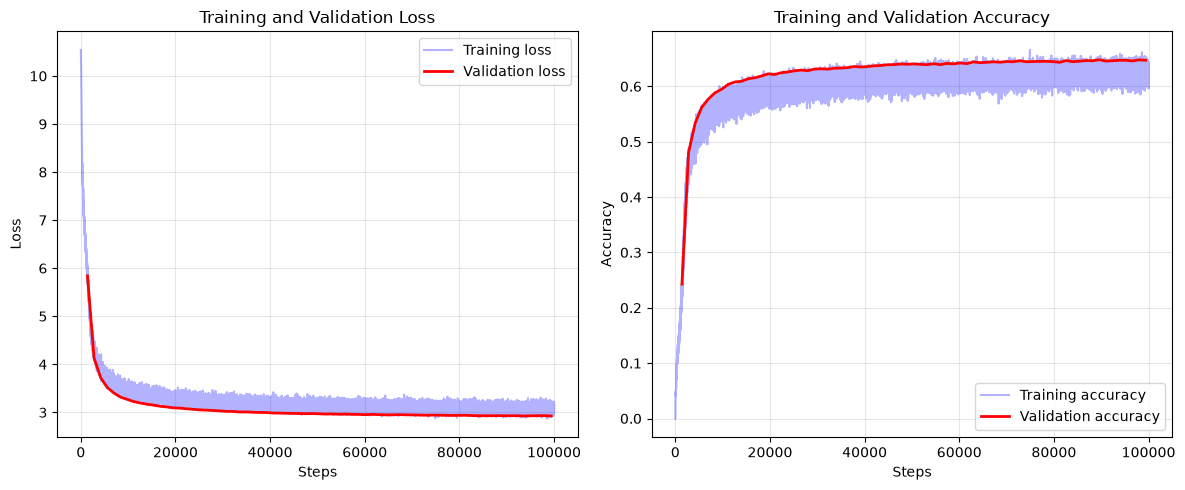

In [57]:
steps = range(len(train_losses))                    # 0 à 99999
val_steps = range(VAL_EVERY, len(train_losses),
                  VAL_EVERY)  # 0, 1000, 2000, ..., 99000

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(steps, train_losses, 'b-', alpha=0.3, label='Training loss')
plt.plot(val_steps, val_losses, 'r-', linewidth=2, label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(steps, train_accs, 'b-', alpha=0.3, label='Training accuracy')
plt.plot(val_steps, val_accs, 'r-', linewidth=2, label='Validation accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Steps')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()